# Robust anytime-valid t-tests: simulation reproducibility

This notebook contains the code for the simulation of the **main-paper experiments first**,
followed by their **supplementary versions with all five priors**. It tests a
Gaussian mean with unknown variance, using a prior on the standardised effect size.

## How to run

Use Python 3.10 or later with NumPy, SciPy, pandas, Matplotlib and a Jupyter
kernel. If needed, install into the environment used by this notebook:

```python
%pip install numpy scipy pandas matplotlib ipykernel
```

Leave `RUN_MODE = "paper"` for the submitted analysis and choose **Restart
Kernel and Run All**. `"quick"` is a smaller diagnostic run, not a source of
publication figures. All code is contained below; no downloaded data or
local Python modules are required. Several minutes of computation may be
needed; timings depend on the machine.

Outputs go into `simulation_outputs/paper_<configuration hash>/` (or
`quick_<hash>/`). Each run writes its configuration, software versions,
actual simulated observations, numerical results, validation report and PDFs.
Main and supplementary figures reuse the same calculations and data.
The notebook is distributed with saved outputs and execution counters cleared.

In [1]:
RUN_MODE = "paper"  # Use "quick" only to test installation and execution.
OUTPUT_ROOT = "simulation_outputs"
DISPLAY_FLOOR = 1e-12  # Figure axis only; stored log p-values are not clipped.

import importlib.util
required = ("numpy", "scipy", "pandas", "matplotlib", "IPython")
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ModuleNotFoundError(
        "Missing notebook dependencies: " + ", ".join(missing) +
        ". Run %pip install numpy scipy pandas matplotlib ipykernel "
        "in a notebook cell, then restart the kernel and run all cells."
    )
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

## Shared model and numerical engine

The observations are independent Gaussian measurements with unknown mean and
variance. We test whether the mean is zero, against a two-sided alternative.
The effect size is the mean divided by the standard deviation. Evidence is
constructed from the scale-invariant likelihood ratio and a fixed prior on
this effect size. All proper priors are two-sided distributions on the whole
real line.

The Gaussian mixture is integrated analytically over effect size. The other
families use their normal scale-mixture representations, with positive
quadrature on log local scale, order refinement and explicit bounds on the
omitted tails. The horseshoe is a Gaussian with a half-Cauchy local scale;
it is not a surrogate density.

Evidence is kept in log units. Failures raise errors instead of silently
returning zero evidence. The requested mixture relative tolerance is 2e-9.
Numerical integration remains necessary for likelihood evaluation;
the null calibration in the next section uses Monte Carlo sampling.

In [2]:
"""Stable full-line invariant t-mixtures for the publication simulations.

Gaussian priors are integrated analytically in effect size. Other priors
are genuine normal-scale mixtures, integrated on the log-scale axis with
quadrature refinement and explicit bounds for both omitted tails.
Refinement checks are numerical diagnostics, not interval arithmetic.
"""
from dataclasses import dataclass
from functools import lru_cache
import math
import numpy as np
from scipy.linalg import eigh_tridiagonal
from scipy.special import exp1, gammaln, log_ndtr, logsumexp, roots_legendre

LOG2PI = math.log(2.0 * math.pi)
MIXTURE_RTOL = 2e-9


@dataclass(frozen=True)
class Prior:
    family: str
    location: float = 0.0
    scale: float = 1.0

    def __post_init__(self):
        if self.family not in ('Gaussian', 'Cauchy', 'Student-t5', 'Laplace', 'Horseshoe'):
            raise ValueError('Unknown prior family: ' + str(self.family))
        if not math.isfinite(self.location) or not math.isfinite(self.scale) or self.scale <= 0:
            raise ValueError('The prior requires finite location and positive finite scale.')


def _check_n(n):
    if isinstance(n, (bool, np.bool_)) or not np.isscalar(n) or not np.isfinite(n) or int(n) != n or n < 2:
        raise ValueError('n must be an integer at least 2.')
    return int(n)


def _invariant(t, n):
    n = _check_n(n)
    t = float(t)
    if not math.isfinite(t):
        raise ValueError('Supply a finite t statistic with positive sample variance.')
    h = math.hypot(math.sqrt(n - 1), t)
    u = math.sqrt(n) * (t / h)
    log_d = math.log(n) + math.log(n - 1) - 2 * math.log(h)
    return u, log_d


def _log_chi_constant(n):
    return (n / 2 - 1) * math.log(2) + gammaln(n / 2)


def _log_j_positive(z, n):
    """log integral r^(n-1) exp(-(r-z)^2/2) dr, z >= 0."""
    z = np.asarray(z, dtype=float)
    log_z = np.full_like(z, -np.inf)
    np.log(z, out=log_z, where=z > 0)
    previous = 0.5 * LOG2PI + log_ndtr(z)
    current = np.logaddexp(-0.5 * z * z, log_z + previous)
    for k in range(1, n - 1):
        previous, current = current, np.logaddexp(log_z + current, math.log(k) + previous)
    return current


@lru_cache(maxsize=512)
def _gamma_rule(n, order):
    """Normalized Gauss-Laguerre rule for Q ~ Gamma(n,1)."""
    j = np.arange(order, dtype=float)
    diagonal = 2 * j + n
    k = np.arange(1, order, dtype=float)
    off_diagonal = np.sqrt(k * (k + n - 1))
    nodes, vectors = eigh_tridiagonal(diagonal, off_diagonal)
    weights = vectors[0] ** 2
    good = weights > 0
    return nodes[good], np.log(weights[good])


def _log_i2_negative(a):
    """log integral r exp(-r^2/2-a*r) dr, avoiding cancellation."""
    a = np.asarray(a, dtype=float)
    result = np.empty_like(a)
    small = a < 10
    if np.any(small):
        aa = a[small]
        log_a = np.full_like(aa, -np.inf)
        np.log(aa, out=log_a, where=aa > 0)
        log_product = log_a + 0.5 * LOG2PI + 0.5 * aa * aa + log_ndtr(-aa)
        result[small] = np.log(-np.expm1(log_product))
    if np.any(~small):
        aa = a[~small]
        inv = 1 / (aa * aa)
        term = np.ones_like(aa)
        total = term.copy()
        for j in range(1, 60):
            term *= -(2 * j + 1) * inv
            total += term
            if np.all(np.abs(term) <= 2e-15 * np.abs(total)):
                break
        if np.any(total <= 0) or np.any(np.abs(term) > 2e-13 * np.abs(total)):
            raise FloatingPointError('The negative n=2 radial expansion failed its remainder check.')
        result[~small] = -2 * np.log(aa) + np.log(total)
    return result


def _log_i_negative(a, n, order=128):
    """log integral r^(n-1) exp(-r^2/2-a*r) dr, a >= 0."""
    a = np.asarray(a, dtype=float)
    if n == 2:
        return _log_i2_negative(a)
    nodes, log_weights = _gamma_rule(n, order)
    shape = a.shape
    aa = a.reshape(-1)
    out = np.empty_like(aa)
    # Chunking bounds temporary memory when refining many local scales.
    for start in range(0, aa.size, 2048):
        part = aa[start:start + 2048]
        rate = np.maximum(part, math.sqrt(n))
        values = ((1 - part[:, None] / rate[:, None]) * nodes[None, :]
                  - 0.5 * (nodes[None, :] / rate[:, None]) ** 2
                  + log_weights[None, :])
        out[start:start + part.size] = (gammaln(n) - n * np.log(rate)
                                               + logsumexp(values, axis=1))
    return out.reshape(shape)


def log_A_n(z, n):
    """Stable log E exp(z R), R ~ chi_n, including large positive z."""
    n = _check_n(n)
    z = np.asarray(z, dtype=float)
    if np.any(~np.isfinite(z)):
        raise ValueError('z must be finite.')
    result = np.empty_like(z)
    positive = z >= 0
    result[positive] = (_log_j_positive(z[positive], n)
                        + 0.5 * z[positive] ** 2 - _log_chi_constant(n))
    if np.any(~positive):
        coarse = _log_i_negative(-z[~positive], n, 64)
        fine = _log_i_negative(-z[~positive], n, 128)
        if np.max(np.abs(coarse - fine)) > 2e-10:
            refined = _log_i_negative(-z[~positive], n, 256)
            if np.max(np.abs(refined - fine)) > 2e-10:
                raise FloatingPointError('Negative radial quadrature failed order refinement.')
            fine = refined
        result[~positive] = fine - _log_chi_constant(n)
    return float(result) if result.ndim == 0 else result


def log_likelihood_ratio(t, n, theta):
    """Full signed-effect invariant likelihood ratio, computed in log space."""
    n = _check_n(n)
    u, log_d = _invariant(t, n)
    theta = np.asarray(theta, dtype=float)
    if np.any(~np.isfinite(theta)):
        raise ValueError('Effect sizes must be finite.')
    z = u * theta
    out = np.empty_like(theta)
    positive = z >= 0
    out[positive] = (-0.5 * np.exp(log_d) * theta[positive] ** 2
                     + _log_j_positive(z[positive], n) - _log_chi_constant(n))
    if np.any(~positive):
        a = -z[~positive]
        coarse = _log_i_negative(a, n, 64)
        fine = _log_i_negative(a, n, 128)
        if np.max(np.abs(coarse - fine)) > 2e-10:
            refined = _log_i_negative(a, n, 256)
            if np.max(np.abs(refined - fine)) > 2e-10:
                raise FloatingPointError('Radial likelihood quadrature did not converge.')
            fine = refined
        out[~positive] = -0.5 * n * theta[~positive] ** 2 + fine - _log_chi_constant(n)
    out[theta == 0] = 0
    if np.any(~np.isfinite(out)):
        raise FloatingPointError('Likelihood ratio is outside numerical range.')
    return float(out) if out.ndim == 0 else out


def log_lebesgue(t, n):
    n = _check_n(n)
    _, log_d = _invariant(t, n)
    return 0.5 * math.log(2 * math.pi / n) + 0.5 * n * (math.log(n) - log_d)


def _log_gaussian_from_log_sd(t, n, location, log_sd, radial_order=128):
    u, log_d = _invariant(t, n)
    log_sd = np.asarray(log_sd, dtype=float)
    log_a = np.logaddexp(0, math.log(n) + 2 * log_sd)
    log_D = np.logaddexp(0, log_d + 2 * log_sd)
    z = location * u * np.exp(-0.5 * (log_a + log_D))
    prefactor = 0.5 * (n - 1) * log_a - 0.5 * n * log_D
    if location * u >= 0:
        # Combine the large opposing exponent terms algebraically, before
        # evaluation: -n*m^2/(2a)+z^2/2 = -m^2*d/[2(1+s^2*d)].
        result = (prefactor - 0.5 * location * location * np.exp(log_d - log_D)
                  + _log_j_positive(z, n) - _log_chi_constant(n))
    else:
        result = (prefactor - 0.5 * n * location * location * np.exp(-log_a)
                  + _log_i_negative(-z, n, radial_order) - _log_chi_constant(n))
    return result


def log_gaussian_mixture(t, n, location=0.0, scale=1.0):
    n = _check_n(n)
    Prior('Gaussian', float(location), float(scale))
    result = _log_gaussian_from_log_sd(t, n, float(location), math.log(scale), 128)
    if location * float(t) < 0 and n > 2:
        refined = _log_gaussian_from_log_sd(t, n, float(location), math.log(scale), 256)
        if abs(float(refined - result)) > 2e-10:
            raise FloatingPointError('Gaussian mixture radial quadrature failed refinement.')
        result = refined
    if not np.isfinite(result):
        raise FloatingPointError('Gaussian mixture is outside numerical range.')
    return float(result)


def _log_scale_weight(x, family):
    """Density of X=log(lambda), where theta|lambda~N(m,s^2 lambda^2)."""
    x = np.asarray(x, dtype=float)
    with np.errstate(over='ignore'):
        if family == 'Cauchy':
            return 0.5 * math.log(2 / math.pi) - x - 0.5 * np.exp(-2 * x)
        if family == 'Student-t5':
            a = 2.5
            return math.log(2) + a * math.log(a) - gammaln(a) - 5 * x - a * np.exp(-2 * x)
        if family == 'Laplace':
            return 2 * x - 0.5 * np.exp(2 * x)
        if family == 'Horseshoe':
            return math.log(2 / math.pi) + x - np.logaddexp(0, 2 * x)
    raise ValueError('No scale mixture for this family.')


def horseshoe_logpdf(x, location=0.0, scale=1.0):
    """Genuine N(m,s^2 lambda^2), lambda~half-Cauchy(0,1), density."""
    Prior('Horseshoe', float(location), float(scale))
    z = (np.asarray(x, dtype=float) - location) / scale
    a = 0.5 * z * z
    result = np.empty_like(a)
    zero = a == 0
    regular = (a < 50) & ~zero
    result[zero] = np.inf
    result[regular] = a[regular] + np.log(exp1(a[regular]))
    large = a >= 50
    if np.any(large):
        aa = a[large]
        term = np.ones_like(aa)
        total = term.copy()
        for k in range(1, 25):
            term *= -k / aa
            total += term
            if np.all(np.abs(term) < 2e-15 * np.abs(total)):
                break
        result[large] = -np.log(aa) + np.log(total)
    result -= math.log(scale) + math.log(math.pi) + 0.5 * LOG2PI
    return float(result) if result.ndim == 0 else result


@lru_cache(maxsize=8)
def _legendre(order):
    nodes, weights = roots_legendre(order)
    return nodes, np.log(weights)


def _scale_integral(t, n, prior, lower, upper, order):
    # Every interval is short enough to resolve both broad half-Cauchy scale
    # tails and the narrow variance-mixture saddle for shifted Laplace priors.
    count = max(1, math.ceil((upper - lower) / 0.5))
    edges = np.linspace(lower, upper, count + 1)
    half = np.diff(edges) / 2
    mid = (edges[:-1] + edges[1:]) / 2
    q, log_w = _legendre(order)
    x = (mid[:, None] + half[:, None] * q).ravel()
    weights = (np.log(half[:, None]) + np.broadcast_to(log_w, (count, order))).ravel()
    log_density = _log_scale_weight(x, prior.family)
    live = np.isfinite(log_density)
    value = _log_gaussian_from_log_sd(t, n, prior.location,
                                      math.log(prior.scale) + x[live],
                                      radial_order=max(64, 4 * order))
    answer = logsumexp(value + log_density[live] + weights[live])
    if not np.isfinite(answer):
        raise FloatingPointError('The normal-scale-mixture integral is not finite.')
    return float(answer), int(np.sum(live))


def _scale_tail_logs(t, n, prior, lower, upper):
    """Upper bounds on omitted lower/upper log-scale mixture contributions."""
    _, log_d = _invariant(t, n)
    # L(theta) <= C exp(-k theta^2), hence L(theta) <= C.
    log_C = 0.5 * n * (math.log(2 * n) - log_d)
    family = prior.family
    if family == 'Horseshoe':
        lower_mass = min(0.0, math.log(2 / math.pi) + lower)
    elif family == 'Laplace':
        lower_mass = min(0.0, 2 * lower - math.log(2))
    elif family == 'Cauchy':
        if -lower > 350:
            lower_mass = -math.inf
        else:
            lower_mass = min(0.0, math.log(2) + float(log_ndtr(-math.exp(-lower))))
    elif family == 'Student-t5':
        # Chernoff bound for Gamma(a,1) exceeding a exp(-2 lower).
        if lower >= 0:
            lower_mass = 0.0
        elif -2 * lower > 700:
            lower_mass = -math.inf
        else:
            a = 2.5
            lower_mass = a * (1 - 2 * lower - math.exp(-2 * lower))
    else:
        raise ValueError('Unknown scale-mixture family.')
    # phi(theta;m,sd) <= 1/(sqrt(2pi)*sd), so integrate the Lebesgue
    # likelihood multiplied by an analytic scale-tail moment bound.
    log_factor = log_lebesgue(t, n) - 0.5 * LOG2PI - math.log(prior.scale)
    if family == 'Horseshoe':
        upper_moment = -math.log(math.pi) - 2 * upper
    elif family == 'Cauchy':
        upper_moment = 0.5 * math.log(2 / math.pi) - math.log(2) - 2 * upper
    elif family == 'Student-t5':
        a = 2.5
        upper_moment = math.log(2) + a * math.log(a) - gammaln(a) - math.log(6) - 6 * upper
    else:
        upper_moment = (-math.inf if upper > 350 else
                        0.5 * LOG2PI + float(log_ndtr(-math.exp(upper))))
    return log_C + lower_mass, log_factor + upper_moment


@dataclass(frozen=True)
class MixtureDiagnostic:
    log_value: float
    relative_refinement_change: float
    relative_omitted_tail_bound: float
    log_scale_lower: float
    log_scale_upper: float
    order: int
    nodes: int


@lru_cache(maxsize=50000)
def log_mixture_with_diagnostics(t, n, prior, rtol=MIXTURE_RTOL):
    n = _check_n(n)
    t = float(t)
    _invariant(t, n)
    if not isinstance(prior, Prior) or not 0 < rtol < 0.01:
        raise ValueError('Supply a Prior and a relative tolerance in (0,0.01).')
    if prior.family == 'Gaussian':
        return MixtureDiagnostic(log_gaussian_mixture(t, n, prior.location, prior.scale),
                                  0.0, 0.0, math.nan, math.nan, 0, 0)
    lower, upper = -6.0, 6.0
    for attempt in range(12):
        coarse, _ = _scale_integral(t, n, prior, lower, upper, 16)
        fine, nodes = _scale_integral(t, n, prior, lower, upper, 32)
        discrepancy = abs(math.expm1(coarse - fine))
        order = 32
        if not math.isfinite(discrepancy) or discrepancy > rtol / 4:
            refined, nodes = _scale_integral(t, n, prior, lower, upper, 64)
            discrepancy = abs(math.expm1(fine - refined))
            fine, order = refined, 64
            if not math.isfinite(discrepancy) or discrepancy > rtol / 4:
                raise FloatingPointError('Normal-scale-mixture quadrature failed order refinement.')
        log_low, log_high = _scale_tail_logs(t, n, prior, lower, upper)
        log_tail = float(np.logaddexp(log_low, log_high))
        if log_tail - fine <= math.log(rtol / 4):
            return MixtureDiagnostic(fine, discrepancy, math.exp(log_tail - fine),
                                      lower, upper, order, nodes)
        target = fine + math.log(rtol / 16)
        _, log_d = _invariant(t, n)
        log_C = 0.5 * n * (math.log(2 * n) - log_d)
        if log_low > target:
            if prior.family == 'Horseshoe':
                lower = min(lower - 2, target - log_C - math.log(2 / math.pi))
            elif prior.family == 'Laplace':
                lower = min(lower - 2, 0.5 * (target - log_C + math.log(2)))
            else:
                lower -= 2
        if log_high > target:
            slope = 6 if prior.family == 'Student-t5' else 2
            upper += max(2, (log_high - target) / slope)
        if not math.isfinite(lower + upper) or upper - lower > 4000:
            raise FloatingPointError('Scale separation exceeds the supported numerical range.')
    raise FloatingPointError('Normal-scale-mixture omitted-tail bounds did not converge.')


def log_mixture(t, n, prior, rtol=MIXTURE_RTOL):
    """Scalar log evidence for a fixed full-line location-scale prior."""
    return log_mixture_with_diagnostics(float(t), _check_n(n), prior, rtol).log_value

### Monte Carlo calibration from two initial observations

Generate one shared sample of **100,000 independent pairs of standard-normal
observations**, using seed `20260510`. These null observations are independent
of both the power datasets and the illustrative trajectory. The same null
pairs are used across priors and prior locations.

At a proposed evidence threshold, divide each simulated initial evidence by
that threshold, cap the ratio at one, and average across the null samples.
This is the Monte Carlo estimate of the extended-Ville calibration. The code
uses a stable log-threshold search, without an artificial positive cutoff floor.

The empirical average is evaluated efficiently using convex bounds on the
evidence at the sampled statistics. The numerical upper/lower brackets concern
**that finite-sample average**, not the population expectation. The upper bracket
is used for calibration and capped by the ordinary Ville bound. This cap uses
the known population inequality and preserves the ordering of the plotted methods.

The requested absolute numerical gap is 1e-5 in paper mode. For trajectory
values it is also at most 0.001 times the empirical upper value. Neither
criterion bounds Monte Carlo sampling error. Calibration standard errors and
a separate 99% uniform Monte Carlo uncertainty band are saved for diagnosis;
the band applies to one fixed prior, uniformly over thresholds.

**Finite Monte Carlo calibration approximates the population procedure.**
The exact anytime-valid guarantee belongs to the population calibration;
Monte Carlo estimates and the Ville cap alone do not establish an exact
finite-simulation error guarantee. Reported standard errors at fitted cutoffs
are descriptive and are not confidence intervals for those cutoffs.

The Lebesgue benchmark retains its analytic evidence and calibration formulas.
No ordinary Ville test is reported for this improper measure.

In [3]:
"""Monte Carlo calibration using shared independent null t statistics.

Convexity provides numerical brackets for the actual empirical calibration
mean. These brackets control numerical integration error, not Monte Carlo
error. Finite Monte Carlo calibration is an approximation to the population
calibration and does not itself establish an exact anytime-valid guarantee.
"""

from dataclasses import dataclass
import math
import numpy as np
from scipy.optimize import brentq



def log_g_lebesgue(log_c):
    """Analytic log calibration for the two-sided full-line Lebesgue mixture."""
    lc = np.asarray(log_c,dtype=float)
    if np.isnan(lc).any():
        raise ValueError("log_c must not contain NaN")
    log_z = np.minimum(0.0,(0.5*math.log(math.pi)-lc)/2.0)
    result = np.empty_like(log_z)
    small = log_z < -20
    result[small] = math.log(4/math.pi)+log_z[small]
    z = np.exp(log_z[~small])
    result[~small] = np.log((2/math.pi)*(np.arcsin(z)+z*np.sqrt(np.maximum(0,1-z*z))))
    return float(result) if result.ndim == 0 else result


def log_threshold_lebesgue(alpha):
    """Invert the analytic Lebesgue calibration in log-threshold units."""
    if not 0 < alpha < 1:
        raise ValueError("Require 0<alpha<1")
    lower = 0.5*math.log(math.pi)
    upper = max(lower+2,2*math.log(4/math.pi/alpha)+lower+2)
    return float(brentq(lambda value: log_g_lebesgue(value)-math.log(alpha),
                        lower,upper,xtol=2e-12,rtol=2e-14))


class NullSample:
    """A reusable finite sample of null t statistics with one degree of freedom."""

    def __init__(self, t_null):
        t = np.asarray(t_null, dtype=float).reshape(-1)
        if t.size < 2 or not np.isfinite(t).all():
            raise ValueError("Provide at least two finite null t statistics")
        self.t = np.sort(t)
        self.B = int(t.size)
        extended_t = self.t.astype(np.longdouble)
        self.u = np.sqrt(np.longdouble(2))*(extended_t/np.hypot(1, extended_t))
        self.prefix_u = np.r_[np.longdouble(0), np.cumsum(self.u, dtype=np.longdouble)]
        self.prefix_u2 = np.r_[np.longdouble(0), np.cumsum(self.u*self.u, dtype=np.longdouble)]

    def centered_moments(self, start, stop, center):
        count = stop-start
        if count <= 0:
            return 0, np.longdouble(0), np.longdouble(0)
        if count <= 256 or self.u[stop-1]-self.u[start] < 1e-3:
            delta = self.u[start:stop]-center
            return count, delta.sum(dtype=np.longdouble), np.dot(delta, delta)
        first = self.prefix_u[stop]-self.prefix_u[start]
        second = self.prefix_u2[stop]-self.prefix_u2[start]
        return count, first-count*center, max(np.longdouble(0), second-2*center*first+count*center*center)

    def dkw_radius(self, delta=0.01):
        """Optional distribution-free MC error diagnostic, not a correction."""
        if not 0 < delta < 1:
            raise ValueError("delta must lie between zero and one")
        return math.sqrt(math.log(2/delta)/(2*self.B))


@dataclass(frozen=True)
class MCResult:
    estimate: float
    lower: float
    upper: float
    gap: float
    mcse: float
    used: float
    ville_bound: float
    intervals: int
    B: int


@dataclass(frozen=True)
class _SampleCell:
    indices: tuple
    logs: tuple


def _unit_exp(log_value):
    return math.exp(min(0.0, float(log_value)))


class MCCalibration:
    """Empirical extended-Ville calibration from a fixed independent sample.

    ``lower`` and ``upper`` bracket the finite-sample calibration mean.
    ``estimate`` and ``mcse`` use the pointwise midpoint of the numerical
    lower and upper functions. The MCSE is descriptive; it is not a
    simultaneous confidence interval or a confidence interval for a root.
    ``used`` is the numerical upper estimate capped by the exact ordinary
    Ville bound. This cap preserves comparison with Ville but does not turn
    the Monte Carlo calibration into an exact population calibration.
    """

    def __init__(self, prior, null_sample, tolerance=1e-6, max_intervals=4096,
                 log_evidence_fn=None, log_mean=0.0):
        if not 0 < tolerance < 1 or max_intervals < 8:
            raise ValueError("Require 0<tolerance<1 and max_intervals>=8")
        self.prior = prior
        self.sample = null_sample if isinstance(null_sample, NullSample) else NullSample(null_sample)
        self.tolerance = float(tolerance)
        self.max_intervals = int(max_intervals)
        self.log_mean = float(log_mean)
        self._callback = log_evidence_fn
        self._values = {}
        self._cells = None
        self._thresholds = {}
        self._tail_cache = {}
        self.max_gap = 0.0

    def _at(self, index):
        index = int(index)
        if index not in self._values:
            t = float(self.sample.t[index])
            value = (log_mixture(t, 2, self.prior) if self._callback is None
                     else self._callback(t))
            if not np.isfinite(value):
                raise FloatingPointError("Nonfinite evidence at a sampled null statistic")
            self._values[index] = float(value)
        return self._values[index]

    def _cell(self, start, stop):
        indices = (int(start), int((start+stop)//2), int(stop))
        return _SampleCell(indices, tuple(self._at(i) for i in indices))

    def _constant_stats(self, start, stop, lower, upper):
        count = stop-start
        midpoint = 0.5*(lower+upper)
        return np.array([count*lower, count*upper, count*midpoint*midpoint], dtype=np.longdouble)

    def _pair_stats(self, start, stop, anchor, low_value, low_slope,
                    high_value, high_slope, threshold):
        """Exact sample moments of two clipped affine functions on an interval."""
        if stop <= start:
            return np.zeros(3, dtype=np.longdouble)
        u = self.sample.u
        cuts = {start, stop}
        for value, slope in [(low_value, low_slope), (high_value, high_slope)]:
            if slope == 0:
                continue
            for level in (np.longdouble(0), threshold):
                difference = level-value
                if abs(difference) > 3*abs(slope):
                    continue
                root = anchor+difference/slope
                k = int(np.searchsorted(u, root, side='left'))
                if start < k < stop:
                    cuts.add(k)
        cuts = sorted(cuts)
        total = np.zeros(3, dtype=np.longdouble)
        for left, right in zip(cuts[:-1], cuts[1:]):
            center = u[(left+right-1)//2]

            def coefficients(value, slope):
                at_center = value+slope*(center-anchor)
                if at_center <= 0:
                    return np.longdouble(0), np.longdouble(0)
                if at_center >= threshold:
                    return np.longdouble(1), np.longdouble(0)
                return at_center/threshold, slope/threshold

            low_a, low_b = coefficients(low_value, low_slope)
            high_a, high_b = coefficients(high_value, high_slope)
            count, first, second = self.sample.centered_moments(left, right, center)
            lower = count*low_a+low_b*first
            upper = count*high_a+high_b*first
            mid_a, mid_b = (low_a+high_a)/2, (low_b+high_b)/2
            moment2 = count*mid_a*mid_a+2*mid_a*mid_b*first+mid_b*mid_b*second
            total += [min(count, max(0, lower)), min(count, max(0, upper)),
                      min(count, max(0, moment2))]
        return total

    def _cell_stats(self, cell, log_c):
        a, m, b = cell.indices
        logs = np.asarray(cell.logs, dtype=np.longdouble)
        u = self.sample.u[[a,m,b]]
        if u[0] == u[2] and self.sample.t[a] != self.sample.t[b]:
            # Near the invariant boundary, distinct finite t values may
            # round to the same U on platforms where longdouble is float64.
            # Evaluate the actual observations rather than declaring a tie.
            values = np.asarray([_unit_exp(self._at(i)-log_c)
                                 for i in range(a,b)],dtype=np.longdouble)
            return np.array([values.sum(),values.sum(),np.dot(values,values)],
                            dtype=np.longdouble)
        if b-a == 1 or u[0] == u[2]:
            value = _unit_exp(logs[0]-log_c)
            return self._constant_stats(a,b,value,value)
        if u[0] == u[1] or u[1] == u[2]:
            return self._constant_stats(a,b,0.0,_unit_exp(max(logs)-log_c))
        shift = max(float(np.max(logs)), float(log_c))
        f = np.exp(logs-np.longdouble(shift))
        threshold = np.exp(np.longdouble(log_c)-shift)
        slopes = np.diff(f)/np.diff(u)
        if not np.isfinite(slopes).all():
            raise FloatingPointError("Nonfinite affine slope in Monte Carlo calibration")
        if threshold < np.longdouble('1e-250'):
            # Resolve extreme relative clipping by whole-interval bounds.
            left_floor = min(f[1], f[1]+slopes[1]*(u[0]-u[1]))
            right_floor = min(f[1], f[1]+slopes[0]*(u[2]-u[1]))
            left_lower = float(left_floor > 0 and np.log(left_floor)+shift >= log_c)
            right_lower = float(right_floor > 0 and np.log(right_floor)+shift >= log_c)
            left_upper = _unit_exp(max(logs[0],logs[1])-log_c)
            right_upper = _unit_exp(max(logs[1],logs[2])-log_c)
            return (self._constant_stats(a,m,left_lower,left_upper)
                    +self._constant_stats(m,b,right_lower,right_upper))
        # Secants bound a convex function above on their own halves;
        # extrapolating the opposite secant gives the lower support.
        left = self._pair_stats(a,m,u[1],f[1],slopes[1],f[1],slopes[0],threshold)
        right = self._pair_stats(m,b,u[1],f[1],slopes[0],f[1],slopes[1],threshold)
        return left+right

    def evaluate(self, log_c, relative_tolerance=None, _absolute_tolerance=None):
        if relative_tolerance is not None and not 0 < relative_tolerance < 1:
            raise ValueError("relative_tolerance must lie between zero and one")
        lc = float(log_c)
        absolute_tolerance = (self.tolerance if _absolute_tolerance is None
                              else float(_absolute_tolerance))
        if math.isnan(lc):
            raise ValueError("log_c must not be NaN")
        if not math.isfinite(lc):
            value = 1.0 if lc < 0 else 0.0
            return MCResult(value,value,value,0.0,0.0,value,value,0,self.sample.B)
        endpoint_max = max(self._at(0),self._at(self.sample.B-1))
        if lc > endpoint_max:
            factor = math.exp(endpoint_max-lc)
            anchor_tolerance = math.exp(min(0.0,math.log(absolute_tolerance)+lc-endpoint_max))
            cached = self._tail_cache.get(relative_tolerance)
            if cached is None or cached.gap > anchor_tolerance:
                self._tail_cache[relative_tolerance] = self.evaluate(
                    endpoint_max,relative_tolerance=relative_tolerance,
                    _absolute_tolerance=anchor_tolerance)
            anchor = self._tail_cache[relative_tolerance]
            lower,upper = anchor.lower*factor,anchor.upper*factor
            ville = _unit_exp(self.log_mean-lc)
            if _absolute_tolerance is None:
                self.max_gap = max(self.max_gap,anchor.gap*factor)
            return MCResult(anchor.estimate*factor,lower,upper,anchor.gap*factor,
                            anchor.mcse*factor,min(upper,ville),ville,
                            anchor.intervals,self.sample.B)
        if self._cells is None:
            edges = np.unique(np.linspace(0,self.sample.B-1,9,dtype=int))
            self._cells = [self._cell(a,b) for a,b in zip(edges[:-1],edges[1:])]
        cells = self._cells
        stats = [self._cell_stats(cell,lc) for cell in cells]
        # Each cell includes its left endpoint and excludes its right one.
        # Include the single maximum observation separately.
        last = np.longdouble(_unit_exp(self._at(self.sample.B-1)-lc))
        total = np.sum(stats,axis=0,dtype=np.longdouble)+[last,last,last*last]
        B = self.sample.B
        while True:
            lower,upper = float(total[0]/B),float(total[1]/B)
            if lower > upper+1e-9:
                raise FloatingPointError("Empirical calibration bounds crossed")
            lower = min(lower,upper)
            gap = max(0.0,upper-lower)
            requested = absolute_tolerance
            if relative_tolerance is not None and upper > 0:
                requested = min(requested,relative_tolerance*upper)
            if gap <= requested:
                break
            if len(cells) >= self.max_intervals:
                raise FloatingPointError(f"Empirical calibration gap {gap:.3g} exceeds {requested:.3g}; increase max_intervals")
            j = max(range(len(stats)),key=lambda k: stats[k][1]-stats[k][0])
            a,m,b = cells[j].indices
            if m == a or m == b:
                raise FloatingPointError("Sample interval cannot be refined further")
            left,right = self._cell(a,m),self._cell(m,b)
            ls,rs = self._cell_stats(left,lc),self._cell_stats(right,lc)
            total += ls+rs-stats[j]
            cells[j],stats[j] = left,ls
            cells.append(right)
            stats.append(rs)
        estimate = 0.5*(lower+upper)
        second = float(total[2]/B)
        mcse = math.sqrt(max(0.0,second-estimate*estimate)/(B-1))
        ville = _unit_exp(self.log_mean-lc)
        if _absolute_tolerance is None:
            self.max_gap = max(self.max_gap,gap)
        return MCResult(estimate,lower,upper,gap,mcse,min(upper,ville),ville,len(cells),B)

    def log_upper(self, log_c, relative_tolerance=None):
        """Log of the numerical upper MC calibration capped by Ville."""
        lc = float(log_c)
        endpoint_max = max(self._at(0),self._at(self.sample.B-1))
        if math.isfinite(lc) and lc > endpoint_max:
            # All sampled evidence is below c. The empirical calibration
            # equals its value at the endpoint maximum times exp(anchor-lc).
            self.evaluate(lc,relative_tolerance=relative_tolerance)
            anchor = self._tail_cache[relative_tolerance]
            return min(math.log(anchor.upper)+endpoint_max-lc,self.log_mean-lc,0.0)
        value = self.evaluate(lc,relative_tolerance=relative_tolerance).used
        return math.log(value) if value > 0 else -math.inf

    def log_threshold(self, alpha, log_tolerance=2e-7):
        if not 0 < alpha < 1:
            raise ValueError("Require 0<alpha<1")
        alpha = float(alpha)
        if alpha in self._thresholds:
            return self._thresholds[alpha]
        high = float(np.nextafter(self.log_mean-math.log(alpha),math.inf))
        low,step = high-2.0,2.0
        for _ in range(80):
            if self.evaluate(low).used > alpha:
                break
            high = low
            step *= 2
            low -= step
        else:
            raise FloatingPointError("Could not bracket empirical log threshold")
        for _ in range(80):
            middle = (low+high)/2
            if self.evaluate(middle).used <= alpha:
                high = middle
            else:
                low = middle
            if high-low <= log_tolerance:
                break
        if self.evaluate(high).used > alpha*(1+1e-12):
            raise FloatingPointError("Returned empirical threshold failed its check")
        self._thresholds[alpha] = high
        return high

    threshold = log_threshold

    def evaluate_many(self, log_c, relative_tolerance=None):
        values = np.asarray(log_c,dtype=float)
        unique,inverse = np.unique(values,return_inverse=True)
        results = [self.evaluate(x,relative_tolerance=relative_tolerance) for x in unique]
        return [results[i] for i in inverse]


Calibrator = MCCalibration

### Experiment helpers

To avoid unchecked interpolation in the power calculation, rejection counts
are obtained from the actual sorted simulated t statistics. Convexity of the
evidence in the invariant statistic makes its sublevel set an interval.
Binary searches locate the two rejection tails, including any duplicate
statistics. Independent checks compare the counts with direct evaluation.

Sample variances are computed from centred observations. Positive rescaling
is used internally to avoid overflow, without changing the statistic.

In [4]:
"""Reproducible fixed-time power and single-stream anytime-valid t-test plots."""
from dataclasses import asdict
from pathlib import Path
import hashlib
import json
import platform
import sys
import time
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D



IMPLEMENTATION_VERSION = "2026-11-21-monte-carlo-v1"
MAIN_PRIORS = ("Gaussian", "Cauchy", "Student-t5")
ALL_PRIORS = MAIN_PRIORS + ("Laplace", "Horseshoe")
PRIOR_SCALES = {"Gaussian": 1.0, "Cauchy": 1 / np.sqrt(2),
                "Student-t5": 1.0, "Laplace": 1.0, "Horseshoe": 1.0}
PRIOR_COLORS = {"Gaussian": "#2682B5", "Cauchy": "#D43F3A",
                "Student-t5": "#E58B21", "Laplace": "#348B67",
                "Horseshoe": "#8758A5"}
PRIOR_LABELS = {**{p: p for p in ALL_PRIORS}, "Student-t5": "Student-t₅"}


def simulation_config(mode="paper"):
    if mode not in ("paper", "quick"):
        raise ValueError("mode must be 'paper' or 'quick'")
    paper = mode == "paper"
    locations = np.unique(np.r_[np.linspace(-30, 30, 25),
                                [-2, -1, -.5, 0, .5, 1, 2, 4]]).tolist()
    return dict(mode=mode, implementation_version=IMPLEMENTATION_VERSION,
                theta_star=.5, sampling_model="Y_i iid N(theta_star, 1); test mu=0",
                alpha_power=.10, alpha_trajectory=.05, n0=2,
                seed_power=20260508, seed_trajectory=20260509,
                seed_calibration=20260510,
                calibration_replicates=100000 if paper else 2000,
                calibration_mc_delta=.01,
                replicates=10000 if paper else 200,
                n_values=[20, 50, 100, 150] if paper else [20, 50],
                locations=locations if paper else [-8.0, .5, 8.0],
                trajectory_n=150 if paper else 35,
                trajectory_locations=[.5, 2.0, 8.0, 32.0] if paper else [.5, 8.0],
                prior_scales=PRIOR_SCALES,
                evidence_relative_tolerance=MIXTURE_RTOL,
                calibration_numerical_tolerance=1e-5 if paper else 5e-5,
                trajectory_calibration_relative_tolerance=1e-3,
                calibration_max_intervals=4096,
                calibration_definition="Monte Carlo mean; numerical upper bracket capped by Ville",
                power_definition="fixed-time rejection probability",
                trajectory_definition="one fixed stream; running minimum p-values")


def t_statistic(y, axis=-1):
    """Student statistic, using centered sample variance and scale normalization.

    Normalizing each data vector first avoids overflow/underflow when checking
    scale invariance. Constant/nonfinite observations fail explicitly.
    """
    values = np.asarray(y, dtype=float)
    if values.ndim == 0 or values.shape[axis] < 2 or not np.isfinite(values).all():
        raise ValueError("At least two finite observations are required")
    scale = np.max(np.abs(values), axis=axis, keepdims=True)
    if np.any(scale == 0):
        raise ValueError("Sample variance is zero")
    z = values / scale
    sd = np.std(z, axis=axis, ddof=1)
    if np.any(sd <= 0) or not np.isfinite(sd).all():
        raise ValueError("Positive finite sample variance is required")
    out = np.sqrt(values.shape[axis]) * np.mean(z, axis=axis) / sd
    if not np.isfinite(out).all():
        raise FloatingPointError("The t statistic exceeds floating-point range")
    return float(out) if np.ndim(out) == 0 else out


def count_rejections_unimodal(sorted_t, n, prior, log_thresholds):
    """Exact empirical counts up to evidence evaluation error; no interpolation.

    M_n is convex in U_n, and U_n is strictly increasing in T_n. Consequently
    its sublevel set is an interval. Binary search finds the minimum and
    both threshold crossings among the actual sorted simulated statistics.
    """
    x = np.asarray(sorted_t, dtype=float)
    cuts = np.atleast_1d(np.asarray(log_thresholds, dtype=float))
    if x.ndim != 1 or len(x) < 1 or not np.isfinite(x).all() or np.any(np.diff(x) < 0):
        raise ValueError("Supply a nonempty sorted vector of finite t statistics")
    if not np.isfinite(cuts).all():
        raise ValueError("Supply finite log thresholds")
    x, multiplicities = np.unique(x, return_counts=True)
    cumulative = np.r_[0, np.cumsum(multiplicities)]
    values = {}

    def f(i):
        if i not in values:
            values[i] = log_mixture(float(x[i]), n, prior)
        return values[i]

    size = len(x)
    left, right = 0, size - 1
    while left < right:
        mid = (left + right) // 2
        if f(mid) <= f(mid + 1):
            right = mid
        else:
            left = mid + 1
    minimum = left
    counts = []
    for cut in cuts:
        if f(minimum) >= cut:
            counts.append(int(cumulative[-1]))
            continue
        left, right = 0, minimum
        while left < right:
            mid = (left + right) // 2
            if f(mid) >= cut:
                left = mid + 1
            else:
                right = mid
        left_count = left
        left, right = minimum + 1, size
        while left < right:
            mid = (left + right) // 2
            if f(mid) < cut:
                left = mid + 1
            else:
                right = mid
        counts.append(int(cumulative[left_count] + cumulative[-1] - cumulative[left]))
    return np.asarray(counts, dtype=int)


def _write_csv(rows, path):
    path = Path(path)
    temporary = path.with_suffix(".tmp.csv")
    pd.DataFrame(rows).to_csv(temporary, index=False)
    temporary.replace(path)


class SimulationRun:
    """One shared data draw, reusable calibrations, and incremental outputs."""
    def __init__(self, config, output_root="simulation_outputs"):
        self.config = dict(config)
        self.identity = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
        self.output = Path(output_root) / f"{config['mode']}_{self.identity}"
        self.output.mkdir(parents=True, exist_ok=True)
        self.figures = self.output / "figures"
        self.figures.mkdir(exist_ok=True)
        (self.output / "config.json").write_text(json.dumps(config, indent=2) + "\n")
        versions = dict(python=sys.version, platform=platform.platform(),
                        numpy=np.__version__, scipy=scipy.__version__,
                        pandas=pd.__version__, matplotlib=matplotlib.__version__)
        (self.output / "versions.json").write_text(json.dumps(versions, indent=2) + "\n")
        rng_power = np.random.default_rng(config['seed_power'])
        self.y_power = rng_power.normal(config['theta_star'], 1.0,
                                       (config['replicates'], max(config['n_values'])))
        self.y_calibration = np.random.default_rng(config['seed_calibration']).normal(
            0.0, 1.0, (config['calibration_replicates'], 2))
        self.null_sample = NullSample(t_statistic(self.y_calibration))
        self.mc_uniform_radius = np.sqrt(
            np.log(2 / config['calibration_mc_delta']) / (2 * config['calibration_replicates']))
        self.y_trajectory = np.random.default_rng(config['seed_trajectory']).normal(
            config['theta_star'], 1.0, config['trajectory_n'])
        # Save the actual observations as well as seeds, for exact replotting.
        np.savez_compressed(self.output / "simulated_observations.npz",
                            power=self.y_power, trajectory=self.y_trajectory,
                            calibration_null_pairs=self.y_calibration)
        self.sorted_t = {n: np.sort(t_statistic(self.y_power[:, :n])) for n in config['n_values']}
        self.ns = np.arange(config['n0'], config['trajectory_n'] + 1)
        self.trajectory_t = np.array([t_statistic(self.y_trajectory[:n]) for n in self.ns])
        self.power_rows, self.trajectory_rows, self.calibration_rows = [], [], []
        self._calibrators = {}
        self._done_power, self._done_trajectory = set(), set()
        self._add_lebesgue()

    def prior(self, family, location):
        return Prior(family, float(location), self.config['prior_scales'][family])

    def calibrator(self, prior):
        if prior not in self._calibrators:
            self._calibrators[prior] = MCCalibration(
                prior, self.null_sample, tolerance=self.config['calibration_numerical_tolerance'],
                max_intervals=self.config['calibration_max_intervals'])
        return self._calibrators[prior]

    def _add_lebesgue(self):
        cfg = self.config
        cutoff = log_threshold_lebesgue(cfg['alpha_power'])
        for n in cfg['n_values']:
            evidence = np.array([log_lebesgue(t, n) for t in self.sorted_t[n]])
            rejected = int(np.sum(evidence >= cutoff))
            p = rejected / cfg['replicates']
            self.power_rows.append(dict(prior="Lebesgue", location=np.nan, scale=np.nan,
                n=n, method="eVille", alpha=cfg['alpha_power'], rejected=rejected,
                replicates=cfg['replicates'], power=p,
                mcse=np.sqrt(p*(1-p)/cfg['replicates']), log_threshold=cutoff))
        evidence = np.array([log_lebesgue(t, int(n)) for t, n in zip(self.trajectory_t, self.ns)])
        running = np.maximum.accumulate(evidence)
        logs = log_g_lebesgue(running)
        for n, t, le, lr, lp in zip(self.ns, self.trajectory_t, evidence, running, logs):
            self.trajectory_rows.append(dict(prior="Lebesgue", location=np.nan, scale=np.nan,
                n=int(n), t_statistic=t, log_evidence=le, running_log_evidence=lr,
                method="eVille", log_p=lp, p_value=np.exp(lp),
                mc_estimate=np.nan, mcse=np.nan, empirical_lower=np.nan, empirical_upper=np.nan,
                numerical_gap=0.0, calibration_kind="analytic Lebesgue"))
        self.save()

    def run_power(self, families):
        cfg = self.config
        for family in families:
            start = time.perf_counter()
            for location in cfg['locations']:
                key = (family, float(location))
                if key in self._done_power:
                    continue
                prior = self.prior(*key)
                calibration = self.calibrator(prior)
                log_e = calibration.log_threshold(cfg['alpha_power'])
                log_v = -np.log(cfg['alpha_power'])
                check = calibration.evaluate(log_e)
                if log_e > log_v + 1e-6 or check.used > cfg['alpha_power'] + 1e-12:
                    raise AssertionError("Threshold dominance/calibration check failed")
                self.calibration_rows.append(dict(**asdict(prior), alpha=cfg['alpha_power'],
                    log_threshold_eVille=log_e, log_threshold_Ville=log_v,
                    mc_estimate=check.estimate, empirical_lower=check.lower, empirical_upper=check.upper,
                    calibrated_value=check.used, numerical_gap=check.gap, mcse=check.mcse,
                    calibration_replicates=cfg['calibration_replicates'], intervals=check.intervals,
                    mc_uniform_radius=self.mc_uniform_radius,
                    population_lower_diagnostic=max(0.0, check.lower-self.mc_uniform_radius),
                    population_upper_diagnostic=min(1.0, check.upper+self.mc_uniform_radius)))
                for n in cfg['n_values']:
                    counts = count_rejections_unimodal(self.sorted_t[n], n, prior, [log_e, log_v])
                    if counts[0] < counts[1]:
                        raise AssertionError("eVille rejected fewer streams than Ville")
                    for method, count, cutoff in zip(("eVille", "Ville"), counts, (log_e, log_v)):
                        p = count / cfg['replicates']
                        self.power_rows.append(dict(prior=family, location=location, scale=prior.scale,
                            n=n, method=method, alpha=cfg['alpha_power'], rejected=int(count),
                            replicates=cfg['replicates'], power=p,
                            mcse=np.sqrt(p*(1-p)/cfg['replicates']), log_threshold=cutoff))
                self._done_power.add(key)
                self.save()
            print(f"Power: {family} completed ({time.perf_counter()-start:.1f} seconds)", flush=True)
        return pd.DataFrame(self.power_rows)

    def run_trajectories(self, families):
        cfg = self.config
        for family in families:
            start = time.perf_counter()
            for location in cfg['trajectory_locations']:
                key = (family, float(location))
                if key in self._done_trajectory:
                    continue
                prior = self.prior(*key)
                calibration = self.calibrator(prior)
                logs = np.array([log_mixture(t, int(n), prior)
                                 for t, n in zip(self.trajectory_t, self.ns)])
                running = np.maximum.accumulate(logs)
                log_v = np.minimum(0.0, -running)
                # Evaluate the same empirical null calibration at each new maximum.
                # Its numerical brackets are not confidence bounds for population g.
                unique, inverse = np.unique(running, return_inverse=True)
                reltol = cfg['trajectory_calibration_relative_tolerance']
                brackets = [calibration.evaluate(v, relative_tolerance=reltol) for v in unique]
                log_used = np.array([
                    np.log(b.used) if b.used > 0 else calibration.log_upper(v, relative_tolerance=reltol)
                    for b, v in zip(brackets, unique)])[inverse]
                log_e = np.minimum.accumulate(np.minimum(log_used, log_v))
                if np.any(log_e > log_v + 1e-12) or np.any(np.diff(log_e) > 1e-12):
                    raise AssertionError("Running Monte Carlo p-values failed their numerical ordering")
                for j, n in enumerate(self.ns):
                    b = brackets[inverse[j]]
                    base = dict(prior=family, location=location, scale=prior.scale, n=int(n),
                                t_statistic=self.trajectory_t[j], log_evidence=logs[j],
                                running_log_evidence=running[j])
                    self.trajectory_rows.append(dict(**base, method="eVille", log_p=log_e[j],
                        p_value=np.exp(log_e[j]), mc_estimate=b.estimate, mcse=b.mcse,
                        empirical_lower=b.lower, empirical_upper=b.upper, numerical_gap=b.gap,
                        calibration_kind="Monte Carlo"))
                    self.trajectory_rows.append(dict(**base, method="Ville", log_p=log_v[j],
                        p_value=np.exp(log_v[j]), mc_estimate=np.nan, mcse=np.nan,
                        empirical_lower=np.nan, empirical_upper=np.nan, numerical_gap=np.nan,
                        calibration_kind="Ville"))
                self._done_trajectory.add(key)
                self.save()
            print(f"Trajectory: {family} completed ({time.perf_counter()-start:.1f} seconds)", flush=True)
        return pd.DataFrame(self.trajectory_rows)

    def save(self):
        _write_csv(self.power_rows, self.output / "power.csv")
        _write_csv(self.trajectory_rows, self.output / "trajectory.csv")
        if self.calibration_rows:
            _write_csv(self.calibration_rows, self.output / "calibration.csv")

    def stopping_times(self):
        df = pd.DataFrame(self.trajectory_rows)
        rows = []
        alpha = self.config['alpha_trajectory']
        for (prior, location, method), g in df.groupby(['prior', 'location', 'method'], dropna=False):
            crossed = g.loc[g.log_p <= np.log(alpha), 'n']
            rows.append(dict(prior=prior, location=location, method=method, alpha=alpha,
                first_rejection=int(crossed.min()) if len(crossed) else np.nan,
                rejected_by_horizon=bool(len(crossed)), horizon=self.config['trajectory_n']))
        _write_csv(rows, self.output / "trajectory_stopping_times.csv")
        return pd.DataFrame(rows)


def _style():
    plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 10,
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'axes.labelsize': 11, 'axes.titlesize': 12,
                         'pdf.fonttype': 42, 'ps.fonttype': 42,
                         'savefig.dpi': 150})


def plot_power(run, families, filename):
    _style()
    data = pd.DataFrame(run.power_rows)
    ns = run.config['n_values']
    fig, axes = plt.subplots(2, len(ns), figsize=(3.7*len(ns), 6.0),
                             sharex=True, sharey=True, squeeze=False)
    for row, method in enumerate(("Ville", "eVille")):
        for column, n in enumerate(ns):
            ax = axes[row, column]
            for family in families:
                g = data[(data.prior == family) & (data.n == n) & (data.method == method)].sort_values('location')
                ax.plot(g.location, g.power, '-o', ms=2.5, lw=1.6,
                        color=PRIOR_COLORS[family], label=PRIOR_LABELS[family])
            if method == "eVille":
                p = data[(data.prior == "Lebesgue") & (data.n == n)].power.iloc[0]
                ax.axhline(p, color="black", ls="-.", lw=1.3)
            ax.axvline(run.config['theta_star'], color="0.6", ls="--", lw=.8)
            ax.axhline(run.config['alpha_power'], color="0.65", ls=":", lw=.8)
            ax.set(title=f"{method}, n = {n}", ylim=(-.02, 1.02))
            if column == 0:
                ax.set_ylabel("Fixed-time rejection probability")
            if row == 1:
                ax.set_xlabel("Prior location m")
    handles = [Line2D([0], [0], color=PRIOR_COLORS[p], lw=2, label=PRIOR_LABELS[p]) for p in families]
    handles.append(Line2D([0], [0], color='black', ls='-.', label="Lebesgue (eVille only)"))
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False, bbox_to_anchor=(.5, -.005))
    fig.tight_layout(rect=(0, .065, 1, 1))
    fig.savefig(run.figures / filename, bbox_inches='tight')
    return fig


def plot_trajectories(run, families, filename, display_floor=1e-12):
    """The display floor clips the axis only; stored p-values stay unchanged."""
    _style()
    df = pd.DataFrame(run.trajectory_rows)
    fig, axes = plt.subplots(1, len(families), figsize=(4.2*len(families), 4.3),
                             sharex=True, sharey=True, squeeze=False)
    locations = run.config['trajectory_locations']
    shades = np.linspace(1.0, .35, len(locations))
    leb = df[df.prior == 'Lebesgue'].sort_values('n')
    for ax, family in zip(axes[0], families):
        for opacity, location in zip(shades, locations):
            for method, line in (("eVille", "-"), ("Ville", "--")):
                g = df[(df.prior == family) & (df.location == location) & (df.method == method)].sort_values('n')
                ax.plot(g.n, np.exp(g.log_p),
                        line, color=PRIOR_COLORS[family], alpha=opacity,
                        lw=1.6 if method == 'eVille' else 1.1)
        ax.plot(leb.n, np.exp(leb.log_p), color='black', lw=1.2, ls='-.')
        ax.axhline(run.config['alpha_trajectory'], color='0.45', ls=':', lw=.9)
        ax.set(title=PRIOR_LABELS[family], xlabel='Sample size n', yscale='log',
               ylim=(display_floor, 1.25), xlim=(2, run.config['trajectory_n']))
        # Location shading is explicitly labelled within each prior panel.
        handles = [Line2D([0], [0], color=PRIOR_COLORS[family], alpha=a, lw=2,
                           label=f'm = {m:g}') for a, m in zip(shades, locations)]
        ax.legend(handles=handles, loc='lower left', fontsize=8, frameon=False, ncol=2)
    axes[0, 0].set_ylabel('Running p-value (MC calibration)')
    handles = [Line2D([0], [0], color='0.3', ls='-', label='eVille'),
               Line2D([0], [0], color='0.3', ls='--', label='Ville'),
               Line2D([0], [0], color='black', ls='-.', label='Lebesgue (eVille)'),
               Line2D([0], [0], color='0.45', ls=':', label=f"α = {run.config['alpha_trajectory']:g}")]
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(.5, -.005))
    fig.tight_layout(rect=(0, .08, 1, 1))
    fig.savefig(run.figures / filename, bbox_inches='tight')
    return fig

### Independent checks before simulation

The checks compare mixture evidence with independent analytic identities and
effect-space integration, and the Monte Carlo calibration with direct averages
over the same null samples. They also check tiny thresholds, multiplicative
rescaling, reflection, raw-data scale invariance, sample standard errors, and
accelerated rejection counts against brute force.

Numerical checks diagnose implementation errors. They do not replace the
mathematical validity argument or account for Monte Carlo uncertainty by themselves.

In [5]:
"""Independent checks for finite-null-sample Monte Carlo calibration.

These validate the computation of the empirical calibration, not exact
anytime validity of replacing the population expectation by a sample mean.
Monte Carlo uncertainty and numerical bracketing error are separate.
"""

import json
import math
import time
import warnings
from pathlib import Path

import numpy as np
from scipy.optimize import brentq
from scipy.special import logsumexp, exp1, log_ndtr, gammaln
from scipy.integrate import quad, IntegrationWarning
from scipy.stats import nct, t as student_t, norm, cauchy, laplace



def _check_close(actual, expected, tolerance, label):
    actual, expected = float(actual), float(expected)
    error = abs(actual-expected)
    if not math.isfinite(actual) or not math.isfinite(expected) or error > tolerance:
        raise AssertionError(f"{label}: {actual=}, {expected=}, {error=}, {tolerance=}")
    return error


def _centered_gaussian_reference(t, scale=1.0):
    t = np.asarray(t, dtype=float)
    # n=2 analytic mixture; this independent expression is vectorized.
    return 0.5*np.log1p(2*scale*scale)-np.log1p(2*scale*scale/(1+t*t))


def _empirical_log_g(log_evidence, log_c):
    return float(logsumexp(np.minimum(0.0, np.asarray(log_evidence)-log_c))
                 -math.log(len(log_evidence)))


def _empirical_cutoff(log_evidence, alpha, log_mean=0.0):
    logs = np.asarray(log_evidence)
    raw = brentq(lambda c: _empirical_log_g(logs, c)-math.log(alpha),
                 float(np.min(logs))-1.0,
                 float(np.max(logs))-math.log(alpha)+1.0,
                 xtol=2e-12, rtol=2e-14)
    return min(raw, log_mean-math.log(alpha))


def _check_mc_result(got, logs, log_c, log_mean=0.0):
    weights = np.exp(np.minimum(0.0, np.asarray(logs)-log_c))
    expected = float(np.mean(weights))
    expected_se = float(np.std(weights, ddof=1)/math.sqrt(len(weights)))
    eps = 2e-10
    if not (got.lower <= expected+eps and got.upper >= expected-eps):
        raise AssertionError(f"Empirical mean not bracketed: {got}, mean={expected}")
    _check_close(got.gap, max(0.0, got.upper-got.lower), 2e-12,
                 "Reported empirical numerical gap")
    _check_close(got.estimate, (got.lower+got.upper)/2, 2e-12,
                 "Midpoint empirical estimate")
    ville = math.exp(min(0.0, log_mean-log_c))
    _check_close(got.ville_bound, ville, 2e-12, "Exact mean-based Ville bound")
    _check_close(got.used, min(got.upper, ville), 2e-12,
                 "Numerical Monte Carlo calibration with Ville cap")
    # If the surrogate integrand is the pointwise midpoint, its mean
    # absolute error is at most gap/2. Boundedness in [0,1] then gives
    # |SE_surrogate-SE_exact| <= sqrt(2*gap/(B-1)).
    se_tolerance = math.sqrt(2*max(0.0, got.gap)/(len(weights)-1))+2e-10
    se_error = _check_close(got.mcse, expected_se, se_tolerance,
                            "Monte Carlo standard-error diagnostic")
    return abs(got.estimate-expected), se_error


def run_mc_validation():
    rng = np.random.default_rng(20261122)
    t_null = rng.standard_t(1, size=257)
    sample = NullSample(t_null)
    errors, se_errors = [], []
    for family in ["Gaussian", "Cauchy", "Student-t5", "Laplace", "Horseshoe"]:
        for location in [0.0, 3.0, -3.0]:
            prior = Prior(family, location, 0.7)
            logs = np.array([log_mixture(float(t), 2, prior) for t in t_null])
            cal = MCCalibration(prior, sample, tolerance=1e-7)
            for log_c in [-2.0, 0.0, math.log(10), math.log(100),
                          float(np.median(logs))]:
                got = cal.evaluate(log_c)
                error, se_error = _check_mc_result(got, logs, log_c)
                errors.append(error)
                se_errors.append(se_error)

    # Ties, a constant observed calibration value, and a sample with mean
    # evidence greater than its population mean all need explicit handling.
    corner_checks = 0
    for values in [np.array([0., 0., 0., 1., 1., 1., -1., -1.]),
                   np.repeat(0.5, 12), np.array([10., 20., 30., 40.])]:
        prior = Prior("Gaussian", 0, 1)
        logs = _centered_gaussian_reference(values)
        cal = MCCalibration(prior, NullSample(values), tolerance=1e-8)
        for log_c in [-2.0, 0.1, math.log(10), float(logs[0])]:
            _check_mc_result(cal.evaluate(log_c), logs, log_c)
            corner_checks += 1
    cap_case = MCCalibration(Prior("Gaussian", 0, 1),
                            NullSample(np.array([10., 20., 30., 40.])), tolerance=1e-8)
    capped = cap_case.evaluate(math.log(10))
    if not capped.used < capped.lower:
        raise AssertionError("The exact Ville cap should lie below this raw Monte Carlo bracket")

    root_errors = []
    for family, location, scale in [("Gaussian", 0., 1.),
                                    ("Gaussian", 32., 1.),
                                    ("Cauchy", 8., 1/math.sqrt(2)),
                                    ("Student-t5", -8., 1.),
                                    ("Laplace", 8., 1.),
                                    ("Horseshoe", 8., 1.)]:
        prior = Prior(family, location, scale)
        logs = np.array([log_mixture(float(t), 2, prior) for t in t_null])
        cal = MCCalibration(prior, sample, tolerance=1e-8)
        expected = _empirical_cutoff(logs, .1)
        observed = cal.log_threshold(.1)
        if observed < expected-3e-7:
            raise AssertionError("Numerical cutoff is below the exact empirical cutoff")
        root_errors.append(_check_close(observed, expected, 1e-4,
                                         "Direct finite-sample empirical cutoff"))
        if cal.evaluate(observed).used > .1+2e-10:
            raise AssertionError("Returned empirical cutoff does not satisfy its numerical calibration")

    scale_errors = []
    prior = Prior("Gaussian", 0, 1)
    base_logs = _centered_gaussian_reference(t_null)
    for shift in [-800.0, -50.0, 400.0]:
        cal = MCCalibration(prior, sample, tolerance=1e-8,
                            log_evidence_fn=lambda t, s=shift: float(_centered_gaussian_reference(t))+s,
                            log_mean=shift)
        for base_log_c in [-1.0, 0.5, 3.0]:
            got = cal.evaluate(base_log_c+shift)
            _check_mc_result(got, base_logs+shift, base_log_c+shift, shift)
        expected = _empirical_cutoff(base_logs, .1)
        scale_errors.append(_check_close(cal.log_threshold(.1)-shift, expected, 1e-5,
                                         "Monte Carlo cutoff scale equivariance"))
    constant_log = math.log(1e-20)
    constant = MCCalibration(prior, sample, tolerance=1e-8,
                             log_evidence_fn=lambda t: constant_log,
                             log_mean=constant_log)
    scale_errors.append(_check_close(constant.log_threshold(.1), math.log(1e-19),
                                     3e-7, "Tiny constant Monte Carlo cutoff"))

    tail_log_errors = []
    prior = Prior("Cauchy", 8, 1/math.sqrt(2))
    logs = np.array([log_mixture(float(t), 2, prior) for t in t_null])
    tail = MCCalibration(prior, sample, tolerance=1e-8)
    log_empirical_mean = float(logsumexp(logs)-math.log(len(logs)))
    for log_c in [30.0, 800.0, 1500.0]:
        expected = min(log_empirical_mean-log_c, -log_c, 0.0)
        tail_log_errors.append(_check_close(
            tail.log_upper(log_c, relative_tolerance=1e-5), expected,
            2e-5, "Finite-sample log calibration beyond numerical underflow"))
    tail_log_errors.append(_check_close(constant.log_upper(1000), constant_log-1000,
                                        1e-9, "Constant empirical log calibration below floating-point range"))

    # Check the full publication calibration sample size against the exact
    # empirical sum of an independent analytic Gaussian-mixture formula.
    full_values = rng.standard_t(1, 100000)
    full_logs = _centered_gaussian_reference(full_values, scale=1.3)
    full = MCCalibration(Prior("Gaussian", 0, 1.3), NullSample(full_values),
                         tolerance=1e-7, max_intervals=8192)
    for log_c in [0.0, 0.5, math.log(10)]:
        _check_mc_result(full.evaluate(log_c), full_logs, log_c)

    return {"status": "passed", "checks": {
        "empirical_brackets_all_five_priors": len(errors),
        "ties_constant_and_ville_cap": corner_checks+1,
        "empirical_cutoffs": len(root_errors),
        "multiplicative_scale_checks": 13,
        "log_calibration_below_floating_point_range": len(tail_log_errors),
        "publication_size_empirical_sums": 3},
        "maximum_absolute_errors": {
            "empirical_mean_midpoint": max(errors),
            "mcse": max(se_errors),
            "log_cutoff": max(root_errors),
            "scaled_log_cutoff": max(scale_errors),
            "tiny_log_calibration": max(tail_log_errors)},
        "dkw_diagnostic": {"B":100000, "delta":.01,
            "epsilon": math.sqrt(math.log(2/.01)/(2*100000)),
            "scope":"one fixed prior, uniformly over positive thresholds"},
        "interpretation": "These checks validate empirical Monte Carlo calibration; they do not turn a raw sample mean into an exactly anytime-valid population calibration."}


def _assert_close(observed, expected, atol, description):
    observed = float(observed)
    expected = float(expected)
    error = abs(observed - expected)
    if not np.isfinite(observed) or not np.isfinite(expected) or error > atol:
        raise AssertionError(
            f"{description}: observed={observed:.16g}, expected={expected:.16g}, "
            f"absolute error={error:.4g}, tolerance={atol:.4g}"
        )
    return error

def centered_gaussian_reference(t, n, scale):
    d = n * (n - 1) / ((n - 1) + t * t)
    return ((n - 1) / 2 * np.log1p(n * scale * scale)
            - n / 2 * np.log1p(scale * scale * d))

def shifted_gaussian_reference(t, n, location, scale):
    # Integrating theta first makes sqrt(n)*theta+Z a normal variable with
    # mean sqrt(n)*location and variance 1+n*scale^2. The residual chi-square
    # denominator remains independent, yielding a rescaled noncentral t.
    a = math.sqrt(1 + n * scale * scale)
    return (nct.logpdf(t / a, n - 1, math.sqrt(n) * location / a)
            - math.log(a) - student_t.logpdf(t, n - 1))

def _independent_horseshoe_density(theta, location, scale):
    z = (theta - location) / scale
    if z == 0:
        return math.inf
    a = z * z / 2
    if a < 500:
        scaled_e1 = math.exp(a) * float(exp1(a))
    else:
        # Positive transformed exponential-integral representation.
        scaled_e1, error = quad(lambda v: math.exp(-v) / (a + v),
                                0, math.inf, epsabs=1e-15, epsrel=1e-12)
        if error > max(1e-15, 1e-11 * scaled_e1):
            raise ArithmeticError("Independent horseshoe density did not converge.")
    return scaled_e1 / (math.pi * math.sqrt(2 * math.pi) * scale)

def independent_effect_integral(t, n, prior, limit=12.0):
    """Independent nct likelihood-ratio integration over effect size.

    Cases are restricted to moderate t/n/noncentrality. The Gaussian
    invariant-likelihood envelope bounds the omitted effect-size tails.
    """
    d = n * (n - 1) / ((n - 1) + t * t)
    log_c = n / 2 * math.log(2 * n / d)
    kappa = n * d / (2 * (2 * n - d))
    log_tail_bound = log_c - kappa * limit * limit
    if log_tail_bound > math.log(1e-11):
        raise ValueError("Independent integration window does not bound its tails.")
    base = float(student_t.pdf(t, n - 1))
    if prior.family == "Gaussian":
        logdensity = lambda x: norm.logpdf(x, prior.location, prior.scale)
    elif prior.family == "Cauchy":
        logdensity = lambda x: cauchy.logpdf(x, prior.location, prior.scale)
    elif prior.family == "Student-t5":
        logdensity = lambda x: student_t.logpdf((x - prior.location) / prior.scale, 5) - math.log(prior.scale)
    elif prior.family == "Laplace":
        logdensity = lambda x: laplace.logpdf(x, prior.location, prior.scale)
    elif prior.family == "Horseshoe":
        logdensity = lambda x: math.log(_independent_horseshoe_density(x, prior.location, prior.scale))
    else:
        raise ValueError(prior.family)

    shift = float(logdensity(0.0))
    if not np.isfinite(shift):
        shift = float(logdensity(prior.scale))

    def integrand(theta):
        lr = float(nct.pdf(t, n - 1, math.sqrt(n) * theta)) / base
        return lr * math.exp(logdensity(theta) - shift)

    with warnings.catch_warnings():
        warnings.simplefilter("error", IntegrationWarning)
        value, error = quad(integrand, -limit, limit,
                            points=[prior.location] if abs(prior.location)<limit else None, epsabs=2e-12,
                            epsrel=2e-10, limit=400)
    if not value > 0 or error > max(2e-12, 2e-9 * value):
        raise ArithmeticError("Independent effect integration did not converge.")
    if log_tail_bound-shift > math.log(1e-9*value):
        raise ArithmeticError("Independent tail bound is too large relative to the mixture.")
    return math.log(value)+shift

def run_evidence_validation():
    start = time.perf_counter()
    report = {"checks": {}, "maximum_absolute_log_errors": {}}
    centered_errors = []
    for n in [2, 5, 20, 150]:
        for t in [-8.0, -1.0, 0.0, 1.5, 10.0]:
            for scale in [0.3, 1.0, 3.0]:
                expected = centered_gaussian_reference(t, n, scale)
                centered_errors.append(_assert_close(
                    log_gaussian_mixture(t, n, 0, scale), expected,
                    2e-10, "Centered Gaussian analytic formula"))
    report["checks"]["centered_gaussian"] = len(centered_errors)
    report["maximum_absolute_log_errors"]["centered_gaussian"] = max(centered_errors)

    shifted_errors = []
    for n in [2, 5, 20, 150]:
        for t in [-3.0, 0.0, 3.0]:
            for location in [-2.0, 0.8, 3.0]:
                scale = 1.4
                shifted_errors.append(_assert_close(
                    log_gaussian_mixture(t, n, location, scale),
                    shifted_gaussian_reference(t, n, location, scale),
                    2e-8, "Rescaled noncentral-t Gaussian reference"))
    report["checks"]["shifted_gaussian"] = len(shifted_errors)
    report["maximum_absolute_log_errors"]["shifted_gaussian"] = max(shifted_errors)

    radial_errors = []
    for z in [0.0, 12.0, 35.0, 50.0, 100.0, 200.0]:
        expected = 0.0 if z == 0 else float(np.logaddexp(
            0.0, z*z/2 + math.log(z) + math.log(2*math.pi)/2 + log_ndtr(z)))
        radial_errors.append(_assert_close(log_A_n(z, 2), expected, 2e-10,
                                           "Exact n=2 radial reference"))
    report["checks"]["large_positive_radial"] = len(radial_errors)
    report["maximum_absolute_log_errors"]["large_positive_radial"] = max(radial_errors)

    negative_errors = []
    for a in [0.1, 1.0, 10.0, 100.0, 1000.0]:
        if a < 1:
            value, _ = quad(lambda r: r*math.exp(-r*r/2-a*r),
                             0, math.inf, epsabs=1e-13, epsrel=1e-12)
            expected = math.log(value)
        else:
            value, _ = quad(lambda q: q*math.exp(-q-q*q/(2*a*a)),
                             0, math.inf, epsabs=1e-13, epsrel=1e-12)
            expected = math.log(value) - 2*math.log(a)
        negative_errors.append(_assert_close(log_A_n(-a, 2), expected,
                                              2e-9, "Negative radial scale transform"))
    for n in [5, 20, 150]:
        for a in [0.0, 1.0, 10.0, 1000.0]:
            # Mode-rescaled adaptive integration, independent of the
            # production Gauss--Laguerre representation.
            r = 2*(n-1)/(math.hypot(a, 2*math.sqrt(n-1))+a)
            def radial_integrand(x):
                if x <= 0:
                    return 0.0
                return math.exp((n-1)*math.log(x)-r*r*(x*x-1)/2-a*r*(x-1))
            left, _ = quad(radial_integrand, 0, 1, epsabs=1e-13, epsrel=1e-12)
            right, _ = quad(radial_integrand, 1, math.inf, epsabs=1e-13, epsrel=1e-12)
            expected = (n*math.log(r)-r*r/2-a*r+math.log(left+right)
                        -(n/2-1)*math.log(2)-gammaln(n/2))
            negative_errors.append(_assert_close(log_A_n(-a, n), expected,
                                      2e-9, "Negative radial mode quadrature"))
    report["checks"]["negative_radial"] = len(negative_errors)
    report["maximum_absolute_log_errors"]["negative_radial"] = max(negative_errors)

    independent_errors = []
    reflection_errors = []
    families = ["Gaussian", "Cauchy", "Student-t5", "Laplace", "Horseshoe"]
    for family in families:
        for n, t, location, scale, limit in [(2, 2.0, 0.8, 1.0, 24.0),
                                              (5, -1.3, -2.0, 0.7, 12.0)]:
            prior = Prior(family, location, scale)
            observed = log_mixture(t, n, prior)
            expected = independent_effect_integral(t, n, prior, limit)
            independent_errors.append(_assert_close(
                observed, expected, 5e-7, f"Independent effect integral, {family}"))
            reflected = log_mixture(-t, n, Prior(family, -location, scale))
            reflection_errors.append(_assert_close(
                observed, reflected, 1e-9, f"Reflection identity, {family}"))
    report["checks"]["independent_effect_integrals"] = len(independent_errors)
    report["checks"]["reflection"] = len(reflection_errors)
    report["maximum_absolute_log_errors"]["independent_effect_integrals"] = max(independent_errors)
    report["maximum_absolute_log_errors"]["reflection"] = max(reflection_errors)

    conflict_errors = []
    for family in ["Cauchy", "Student-t5", "Laplace", "Horseshoe"]:
        for location in [50.0, -100.0]:
            prior = Prior(family, location, 1.0)
            observed = log_mixture(-1.3, 5, prior)
            expected = independent_effect_integral(-1.3, 5, prior, 12.0)
            conflict_errors.append(_assert_close(observed, expected, 1e-6,
                                  f"Large prior conflict, {family}"))
    report["checks"]["large_prior_conflict"] = len(conflict_errors)
    report["maximum_absolute_log_errors"]["large_prior_conflict"] = max(conflict_errors)

    hs_errors = []
    for x in [1e-6, 0.1, 1.0, 10.0, 100.0]:
        # Direct local-scale integration is a second representation of the
        # genuine horseshoe density, independent of the E1 expression.
        def local_integrand(v):
            lam = math.exp(v)
            return (2/math.pi) * norm.pdf(x / lam) / (1 + lam*lam)
        value, error = quad(local_integrand, -30, 30, epsabs=1e-12,
                            epsrel=1e-10, limit=250)
        if error > max(1e-12, 1e-9 * value):
            raise ArithmeticError("Horseshoe scale-density check failed.")
        hs_errors.append(_assert_close(horseshoe_logpdf(x), math.log(value),
                                       2e-7, "Genuine horseshoe local-scale density"))
    report["checks"]["horseshoe_density"] = len(hs_errors)
    report["maximum_absolute_log_errors"]["horseshoe_density"] = max(hs_errors)

    leb_errors = []
    for n in [2, 5, 50, 150]:
        for t in [0.0, -4.0, 100.0, 1e8]:
            expected = math.log(2*math.pi/n)/2 + n/2*math.log1p(t*t/(n-1))
            leb_errors.append(_assert_close(log_lebesgue(t, n), expected,
                                            2e-10, "Lebesgue analytic formula"))
    report["checks"]["lebesgue"] = len(leb_errors)
    report["maximum_absolute_log_errors"]["lebesgue"] = max(leb_errors)
    report["elapsed_seconds"] = time.perf_counter() - start
    report["status"] = "passed"
    return report

def run_experiment_validation():
    from scipy.stats import ttest_1samp

    rng = np.random.default_rng(20261121)
    errors = []
    data = rng.normal(0.4, 1.0, (9, 25))
    for n in [2, 5, 25]:
        observed = np.asarray(t_statistic(data[:, :n]))
        expected = np.asarray(ttest_1samp(data[:, :n], 0, axis=1).statistic)
        for actual, reference in zip(observed, expected):
            errors.append(_assert_close(actual, reference, 5e-12,
                                         "Student statistic against scipy"))
        for multiplier in [1e-200, 0.1, 1e200]:
            scaled = np.asarray(t_statistic(multiplier*data[:, :n]))
            for actual, reference in zip(scaled, expected):
                errors.append(_assert_close(actual, reference, 5e-12,
                                             "Positive raw-data scale invariance"))
        transposed = np.asarray(t_statistic(data[:, :n].T, axis=0))
        for actual, reference in zip(transposed, expected):
            errors.append(_assert_close(actual, reference, 5e-12,
                                         "Student statistic axis handling"))

    comparisons = 0
    families = ["Gaussian", "Cauchy", "Student-t5", "Laplace", "Horseshoe"]
    for n in [2, 5, 20]:
        vectors = [np.sort(rng.standard_t(n-1, 39)),
                   np.sort(np.r_[[-5, -2, -1, 0, 0, 0, 1, 2, 5],
                                 [-2, -2, 1, 1, 5]]),
                   np.array([0.5, 0.5, 0.5])]
        for family in families:
            for location in [-3.0, 0.0, 3.0]:
                prior = Prior(family, location, 0.7)
                for values in vectors:
                    evidence = np.array([log_mixture(t, n, prior) for t in values])
                    cuts = np.r_[np.min(evidence)-1, np.max(evidence)+1,
                                 math.log(10), np.quantile(evidence, [0.1, 0.5, 0.9]),
                                 evidence[[0, len(evidence)//2, -1]]]
                    expected = np.array([(evidence >= cut).sum() for cut in cuts])
                    observed = count_rejections_unimodal(values, n, prior, cuts)
                    if not np.array_equal(observed, expected):
                        raise AssertionError(
                            f"Binary counts differ from brute force: {prior}, n={n}, "
                            f"observed={observed}, expected={expected}")
                    comparisons += len(cuts)

    return {"status": "passed",
            "checks": {"student_statistic_and_scale_invariance": len(errors),
                       "unimodal_counts_against_brute_force": comparisons},
            "maximum_absolute_t_error": max(errors)}

In [6]:
validation_report = {
    "evidence": run_evidence_validation(),
    "monte_carlo_calibration": run_mc_validation(),
    "experiment_helpers": run_experiment_validation(),
}
for section, result in validation_report.items():
    print(section, result["status"], result.get("checks", {}))

CONFIG = simulation_config(RUN_MODE)
run = SimulationRun(CONFIG, output_root=OUTPUT_ROOT)
(run.output / "validation_report.json").write_text(
    json.dumps(validation_report, indent=2) + "\n")
print("Output directory:", run.output)
print(json.dumps(CONFIG, indent=2))

evidence passed {'centered_gaussian': 60, 'shifted_gaussian': 36, 'large_positive_radial': 6, 'negative_radial': 17, 'independent_effect_integrals': 10, 'reflection': 10, 'large_prior_conflict': 8, 'horseshoe_density': 5, 'lebesgue': 16}
monte_carlo_calibration passed {'empirical_brackets_all_five_priors': 75, 'ties_constant_and_ville_cap': 13, 'empirical_cutoffs': 6, 'multiplicative_scale_checks': 13, 'log_calibration_below_floating_point_range': 4, 'publication_size_empirical_sums': 3}
experiment_helpers passed {'student_statistic_and_scale_invariance': 135, 'unimodal_counts_against_brute_force': 1215}
Output directory: simulation_outputs/paper_bb38c7533df7
{
  "mode": "paper",
  "implementation_version": "2026-11-21-monte-carlo-v1",
  "theta_star": 0.5,
  "sampling_model": "Y_i iid N(theta_star, 1); test mu=0",
  "alpha_power": 0.1,
  "alpha_trajectory": 0.05,
  "n0": 2,
  "seed_power": 20260508,
  "seed_trajectory": 20260509,
  "seed_calibration": 20260510,
  "calibration_replicate

## 1. Main-paper simulations

### 1.1 Fixed-time power under prior displacement

Generate 10,000 independent streams from a Gaussian distribution with mean
0.5 and variance 1, using seed `20260508`. Use the same streams for all priors
and both calibrations, and nested prefixes at sample sizes 20, 50, 100 and 150.
At nominal level 0.1, report the rejection probability **at that time**, not the
probability of an earlier rejection. Monitoring starts at sample size two.

| Prior | Distribution at location m |
|---|---|
| Gaussian | Mean m, standard deviation 1 |
| Cauchy | Location m, scale 1/sqrt(2) |
| Student-t5 | Location m, 5 degrees of freedom, scale 1 |

The location grid spans -30 to 30, with extra points near the true effect 0.5;
its exact values are saved in `config.json`. `power.csv` contains rejection
counts, estimated power and marginal binomial Monte Carlo standard errors.
These standard errors condition on the calibration sample. They do not include
calibration uncertainty or give standard errors for paired differences.

**Output:** `figures/power_vs_m_priors.pdf`.

Power: Gaussian completed (4.9 seconds)
Power: Cauchy completed (50.5 seconds)
Power: Student-t5 completed (27.1 seconds)


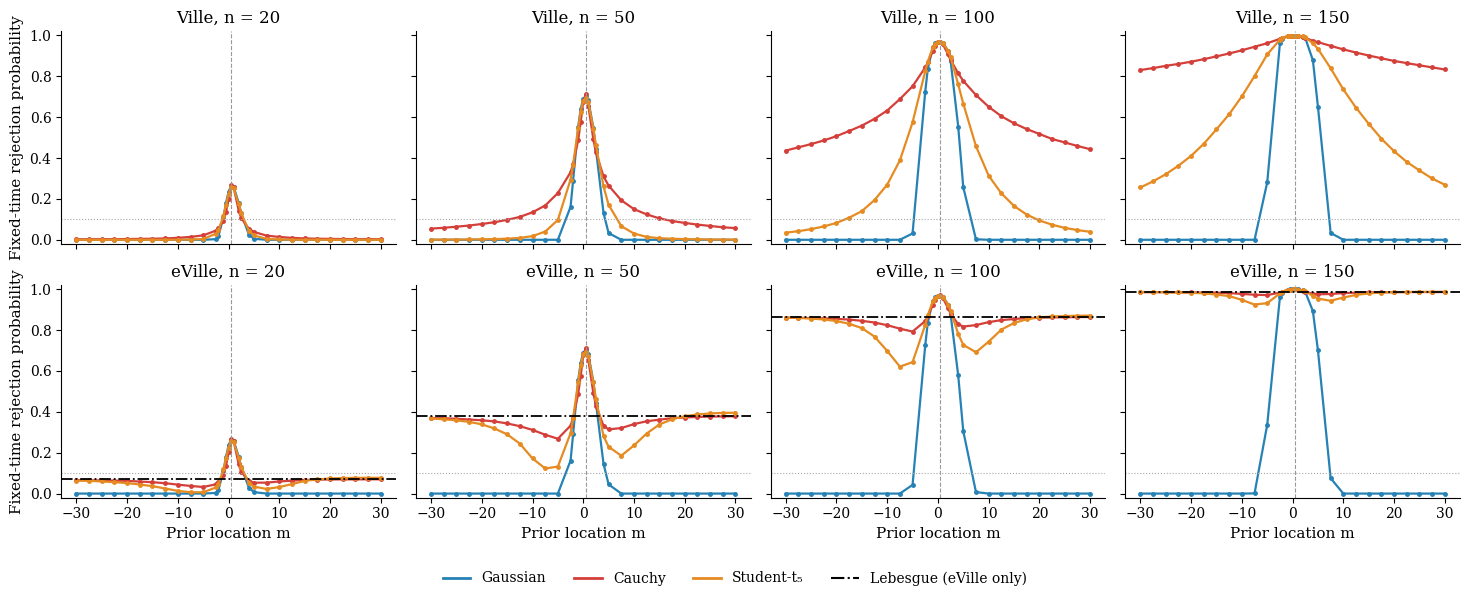

In [7]:
main_power = run.run_power(MAIN_PRIORS)
fig = plot_power(run, MAIN_PRIORS, "power_vs_m_priors.pdf")
plt.show()
plt.close(fig)

### 1.2 Running p-values for one fixed trajectory

Use a separate fixed Gaussian stream with mean 0.5 and variance 1 (seed `20260509`)
and evaluate **every prefix from sample size 2 to 150**. Prior locations are
0.5, 2, 8 and 32. Solid lines show eVille with Monte Carlo calibration; dashed
lines show Ville; the black dot-dashed line shows the analytic Lebesgue benchmark.
The horizontal dotted line is the significance level 0.05.

This is one trajectory, not a median, mean or selected extreme trajectory.
Its first rejection times are descriptive and are not power estimates.
The running minimum of the numerically evaluated Monte Carlo calibration is
used. The figure axis stops at `DISPLAY_FLOOR`; all untruncated log probabilities
remain in `trajectory.csv`.

**Output:** `figures/pvalue_vs_n_simulated.pdf`.

Trajectory: Gaussian completed (0.6 seconds)
Trajectory: Cauchy completed (4.6 seconds)
Trajectory: Student-t5 completed (3.4 seconds)


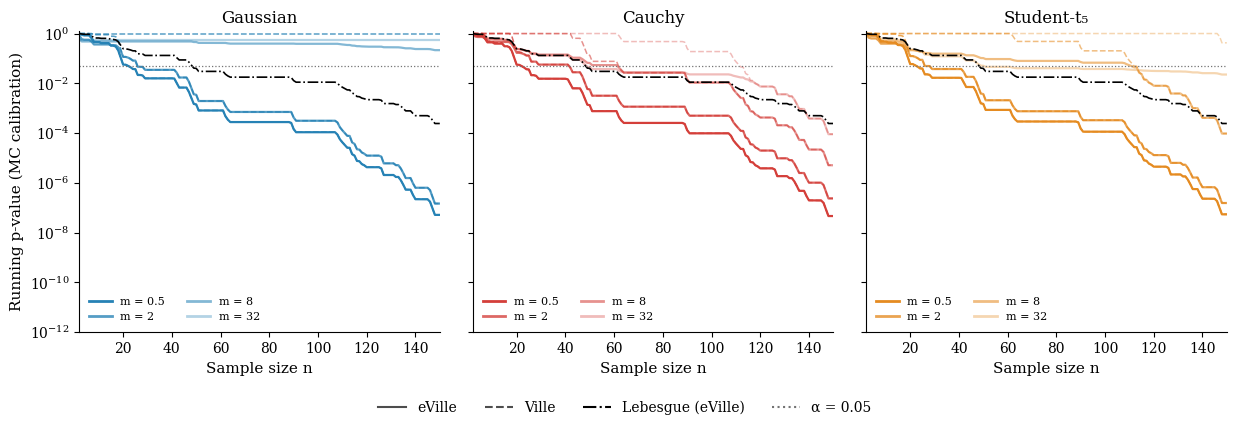

In [8]:
main_trajectory = run.run_trajectories(MAIN_PRIORS)
fig = plot_trajectories(run, MAIN_PRIORS, "pvalue_vs_n_simulated.pdf",
                        display_floor=DISPLAY_FLOOR)
plt.show()
plt.close(fig)

## 2. Supplementary simulations: all five priors

Add the two families below and reuse the Gaussian, Cauchy and Student-t5
results without resimulation or refitting. Data, location grids, scales,
levels and observation order otherwise remain unchanged.

| Additional prior | Distribution at location m |
|---|---|
| Laplace | Location m, scale 1 |
| Horseshoe | Location m, global scale 1; standard Gaussian times independent half-Cauchy local scale |

### 2.1 Fixed-time power for all five priors

**Output:** `figures/power_vs_m_priors_supplement.pdf`.

Power: Gaussian completed (0.0 seconds)
Power: Cauchy completed (0.0 seconds)
Power: Student-t5 completed (0.0 seconds)
Power: Laplace completed (44.0 seconds)
Power: Horseshoe completed (80.7 seconds)


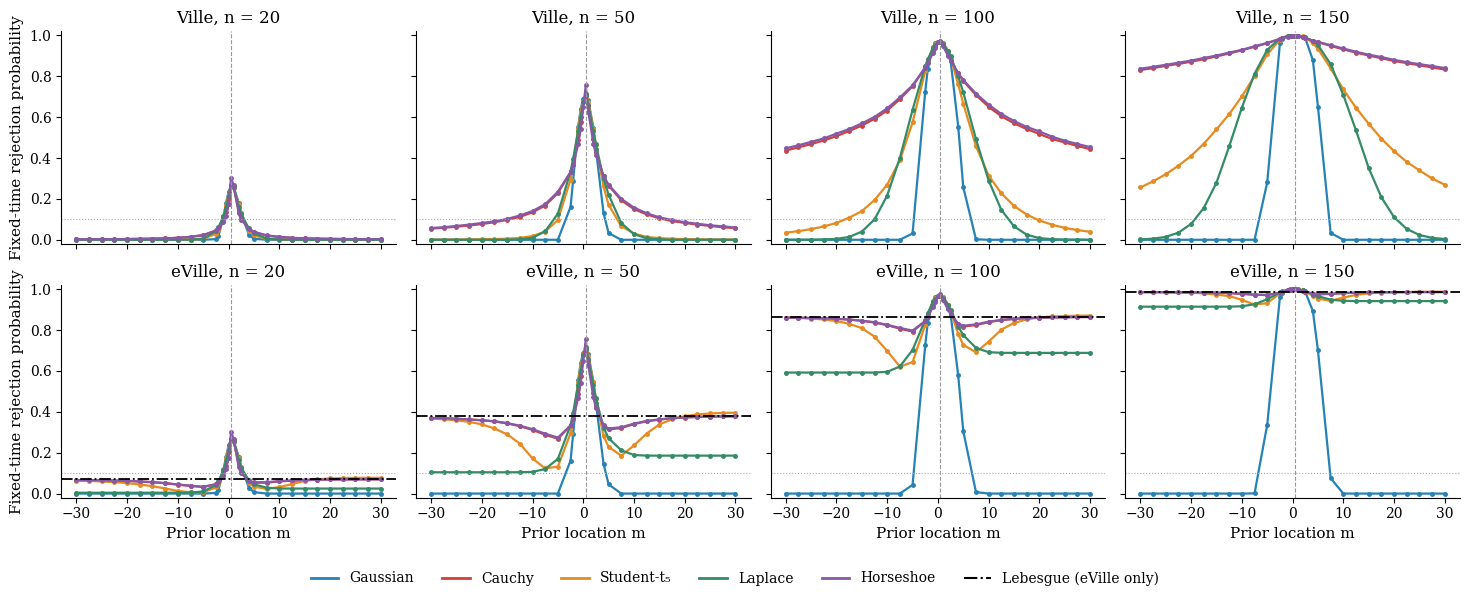

In [9]:
all_power = run.run_power(ALL_PRIORS)  # Existing main-paper rows are reused.
fig = plot_power(run, ALL_PRIORS, "power_vs_m_priors_supplement.pdf")
plt.show()
plt.close(fig)

### 2.2 The same fixed trajectory for all five priors

**Output:** `figures/pvalue_vs_n_simulated_supplement.pdf`.

Trajectory: Gaussian completed (0.0 seconds)
Trajectory: Cauchy completed (0.0 seconds)
Trajectory: Student-t5 completed (0.0 seconds)
Trajectory: Laplace completed (4.3 seconds)
Trajectory: Horseshoe completed (6.8 seconds)


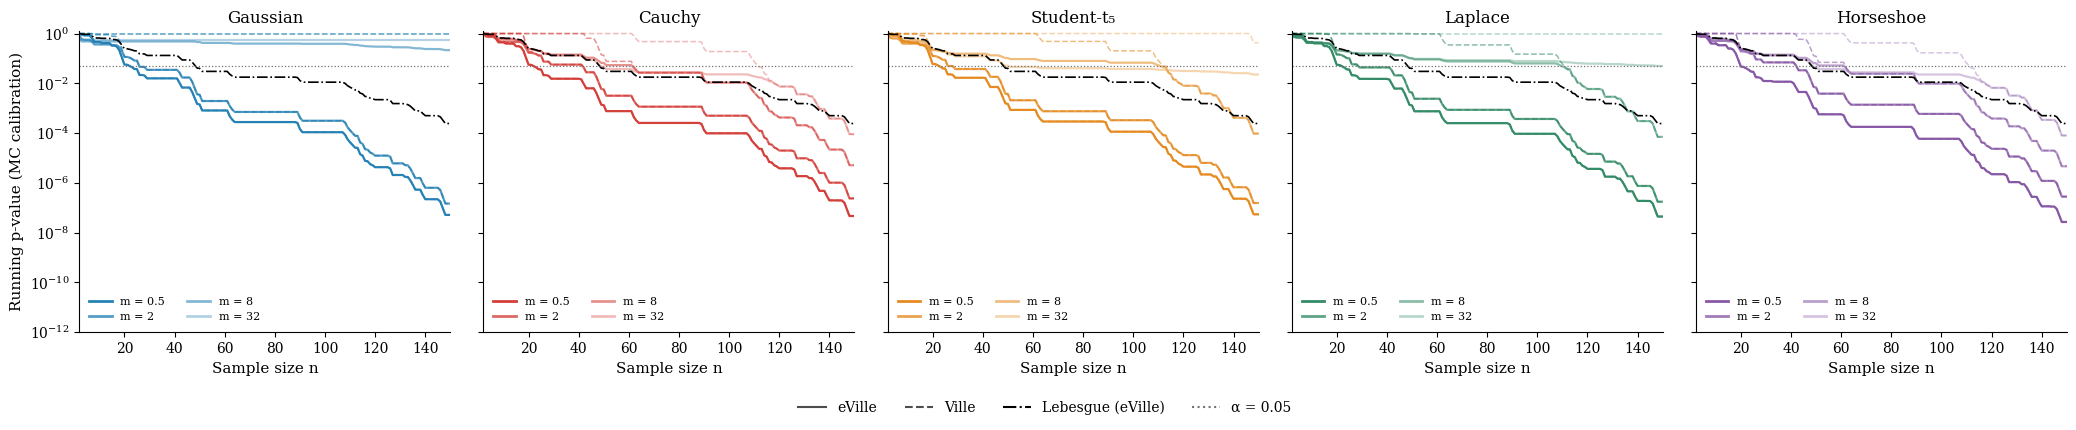

In [10]:
all_trajectory = run.run_trajectories(ALL_PRIORS)
fig = plot_trajectories(run, ALL_PRIORS, "pvalue_vs_n_simulated_supplement.pdf",
                        display_floor=DISPLAY_FLOOR)
plt.show()
plt.close(fig)

## 3. Exported results and checks

`power.csv` contains all fixed-time results. `trajectory.csv` contains every
running value, empirical calibration brackets and Monte Carlo standard errors.
`calibration.csv` contains the power cutoffs and their sampling diagnostics.
The next cell writes first rejection times for the single trajectory. A blank
first rejection time means **no rejection by the horizon**, not rejection at
the final observation.

`simulated_observations.npz` stores the power data, trajectory and null
calibration pairs. `config.json` and `versions.json` record the protocol and
environment. The main and supplementary CSV rows are shared rather than
duplicated. Numerical error and Monte Carlo sampling error are reported separately.

In [11]:
stopping = run.stopping_times()
display(stopping)
power = pd.DataFrame(run.power_rows)
paired = power[power.prior != "Lebesgue"].pivot(
    index=["prior", "location", "n"], columns="method", values="rejected")
assert (paired["eVille"] >= paired["Ville"]).all()
calibration = pd.DataFrame(run.calibration_rows)
assert (calibration.calibrated_value <= calibration.alpha + 1e-12).all()
assert (calibration.numerical_gap <= CONFIG["calibration_numerical_tolerance"] + 1e-12).all()
paths = pd.DataFrame(run.trajectory_rows)
proper_paths = paths[(paths.prior != "Lebesgue") & (paths.method == "eVille")]
assert (proper_paths.numerical_gap <=
        CONFIG["trajectory_calibration_relative_tolerance"] *
        proper_paths.empirical_upper + 1e-14).all()
print("All numerical and experiment-level checks passed.")
print("Maximum power Monte Carlo SE:", power.mcse.max())
print("Maximum calibration Monte Carlo SE:", calibration.mcse.max())
print("Maximum empirical-average numerical gap:", calibration.numerical_gap.max())
print("Per-prior uniform Monte Carlo radius:", run.mc_uniform_radius)
print("Files:")
for path in sorted(run.output.rglob("*")):
    if path.is_file():
        print(" ", path.relative_to(run.output))

,prior,location,method,alpha,first_rejection,rejected_by_horizon,horizon
0,Cauchy,0.5,Ville,0.05,22.0,True,150
1,Cauchy,0.5,eVille,0.05,22.0,True,150
2,Cauchy,2.0,Ville,0.05,42.0,True,150
3,Cauchy,2.0,eVille,0.05,42.0,True,150
4,Cauchy,8.0,Ville,0.05,62.0,True,150
5,Cauchy,8.0,eVille,0.05,62.0,True,150
6,Cauchy,32.0,Ville,0.05,112.0,True,150
7,Cauchy,32.0,eVille,0.05,49.0,True,150
8,Gaussian,0.5,Ville,0.05,23.0,True,150
9,Gaussian,0.5,eVille,0.05,23.0,True,150


All numerical and experiment-level checks passed.
Maximum power Monte Carlo SE: 0.004999806396251759
Maximum calibration Monte Carlo SE: 0.0009465998754698651
Maximum empirical-average numerical gap: 9.966938507299794e-06
Per-prior uniform Monte Carlo radius: 0.005146997846583986
Files:
  calibration.csv
  config.json
  figures/power_vs_m_priors.pdf
  figures/power_vs_m_priors_supplement.pdf
  figures/pvalue_vs_n_simulated.pdf
  figures/pvalue_vs_n_simulated_supplement.pdf
  power.csv
  simulated_observations.npz
  trajectory.csv
  trajectory_stopping_times.csv
  validation_report.json
  versions.json


## 4. Implementation notes

1. `log_mixture_with_diagnostics` evaluates the evidence and reports numerical
   refinement and omitted-tail checks.
2. `MCCalibration.evaluate` approximates the average over the saved random null
   samples. Its lower and upper values bracket that empirical average only.
3. `MCCalibration.log_threshold` searches in log units and retains the
   ordinary Ville threshold as an upper limit.
4. `count_rejections_unimodal` computes fixed-time empirical rejection counts.
5. `SimulationRun.run_trajectories` evaluates the running probabilities on
   the single saved stream.

The uniform sampling-error diagnostic uses the Dvoretzky–Kiefer–Wolfowitz
inequality with Massart's constant. It applies to each fixed prior across all
thresholds; it is not a simultaneous statement across every fitted curve.
It is saved as a diagnostic and is not added to the plotted calibration.
Reference: [Massart (1990), The Tight Constant in the Dvoretzky–Kiefer–Wolfowitz Inequality](https://doi.org/10.1214/aop/1176990746).

A small numerical gap does not imply a small relative Monte Carlo error,
particularly for very small probabilities. Increasing `calibration_replicates`
reduces sampling error; changing the numerical tolerance addresses a different
source of error. The fixed-time power estimates condition on the generated
calibration sample. The code raises errors when its numerical criteria fail.